# AI6101 Reinforcement Learning Assignment — CliffBoxPushing

**Algorithm:** tabular **Q-learning** (off-policy TD control) with ε-greedy exploration.

Contents
1. Environment (unchanged from the template) and the random-agent baseline
2. Q-learning agent (`RLAgent`) — implementation of the TODOs
3. Training and learning progress (episode reward vs. episode)
4. Learned V-table and policy visualisation
5. Evaluation without exploration
6. Action-noise robustness study ($p_{train}, p_{test} \in \{0, 0.1, 0.2\}$)
7. Bonus A — comparison of exploration strategies (ε-greedy, UCB, no exploration)
8. Bonus B — sparse reward (only +1000 at the goal)

Nothing about the game itself (map, reward function, `step()`) is modified. All changes are in the
agent and in the training/evaluation loops, and are listed in Section 2.

In [1]:
from typing import List, Tuple
import copy
import os
import time
import multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
%matplotlib inline

SEED = 6101
np.random.seed(SEED)
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Experiment budgets
MAIN_EPISODES = 15_000          # main agent (same budget as the template)
NOISE_SHORT_EPISODES = 15_000   # robustness study, template budget
NOISE_LONG_EPISODES = 300_000   # robustness study, long budget (action noise slows learning a lot)
NOISE_SEEDS = [0, 1, 2, 3, 4]   # independent training runs per p_train
EVAL_EPISODES = 1_000           # evaluation episodes per (agent, p_test)
BONUS_EPISODES = 15_000
BONUS_SEEDS = [0, 1, 2]

In [2]:
# Plot style: recessive axes, hairline grid, fixed categorical colour order.
SURFACE, INK, INK_2, GRID_INK = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3de'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
CLIFF_COLOR, GOAL_COLOR, BOX_COLOR = '#3b3a37', '#008300', '#eb6834'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
BLUES.set_bad('#f1f0ec')
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID_INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.titlecolor': INK, 'text.color': INK, 'axes.grid': True, 'grid.color': GRID_INK,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
})


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight')


def moving_average(x, window):
    # Trailing moving average (expanding mean for the first window-1 points).
    x = np.asarray(x, dtype=float)
    if window <= 1:
        return x
    c = np.cumsum(np.insert(x, 0, 0.0))
    head = c[1:window] / np.arange(1, window)  # expanding mean until a full window is available
    return np.concatenate([head, (c[window:] - c[:-window]) / window])

The following class defines the grid world environment. The grid world looks like:

```
____________________________________________________________
|___|_0_|_1_|_2_|_3_|_4_|_5_|_6_|_7_|_8_|_9_|_10|_11|_12|_13|
|_0_|___|___|___|_x_|___|___|___|___|___|___|___|_x_|_x_|___|
|_1_|___|_B_|___|_x_|___|___|___|___|___|___|___|___|___|___|
|_2_|___|___|___|_x_|___|___|___|_x_|___|___|___|___|___|___|
|_3_|___|___|___|_x_|___|___|___|_x_|___|___|___|_x_|_x_|___|
|_4_|___|_A_|___|___|___|___|_x_|___|___|___|___|_x_|_x_|_G_|
|_5_|___|___|___|_x_|___|___|_x_|___|___|___|___|_x_|___|___|
```

In [3]:
# Compatibility: NumPy >= 2.5 removed the top-level alias np.chararray used by the renderer below.
# The environment code itself is left unchanged.
import warnings
warnings.filterwarnings('ignore', message='The chararray class is deprecated')
if not hasattr(np, 'chararray'):
    np.chararray = np.char.chararray

In [4]:
AGENT = 'A'
BOX = 'B'
GOAL = 'G'
DANGER = 'x'
GRID = '_'


class CliffBoxGridWorld:
    """
    Cliff Box Pushing Grid World.
    """
    action_space = [1, 2, 3, 4]
    forces = {
        1: np.array([-1, 0]),
        2: np.array([1,  0]),
        3: np.array([0, -1]),
        4: np.array([0,  1]),
    }
    world_width = 14
    world_height = 6
    goal_pos = np.array([4, 13])
    init_agent_pos = np.array([4, 1])
    init_box_pos = np.array([1, 1])
    danger_region = [
        [(0, 3), (3, 3)],
        [(5, 3), (5, 3)],
        [(4, 6), (5, 6)],
        [(2, 7), (3, 7)],
        [(0, 11), (0, 11)],
        [(3, 11), (5, 11)],
        [(0, 12), (0, 12)],
        [(3, 12), (4, 12)],
    ]

    def __init__(self,
                 episode_length=100,
                 render=False,
                 ):
        """
        The grid world looks like:
        ____________________________________________________________
        |___|_0_|_1_|_2_|_3_|_4_|_5_|_6_|_7_|_8_|_9_|_10|_11|_12|_13|
        |_0_|___|___|___|_x_|___|___|___|___|___|___|___|_x_|_x_|___|
        |_1_|___|_B_|___|_x_|___|___|___|___|___|___|___|___|___|___|
        |_2_|___|___|___|_x_|___|___|___|_x_|___|___|___|___|___|___|
        |_3_|___|___|___|_x_|___|___|___|_x_|___|___|___|_x_|_x_|___|
        |_4_|___|_A_|___|___|___|___|_x_|___|___|___|___|_x_|_x_|_G_|
        |_5_|___|___|___|_x_|___|___|_x_|___|___|___|___|_x_|___|___|
        """
        # Environment configurations.
        self.episode_length = episode_length
        self.render = render
        self.agent_pos = self.init_agent_pos
        self.box_pos = self.init_box_pos

        # Visualization.
        if self.render:
            self.world = np.chararray((self.world_height, self.world_width))
            self.last_agent_pos = copy.deepcopy(self.agent_pos)
            self.last_box_pos = copy.deepcopy(self.box_pos)
            self.world[:] = GRID
            for region in self.danger_region:
                A, B = region
                assert A[1] == B[1], "A[1] != B[1]"
                self.world[A[0]:B[0]+1, A[1]] = DANGER
            self.world[self.agent_pos[0], self.agent_pos[1]] = AGENT
            self.world[self.box_pos[0], self.box_pos[1]] = BOX
            self.world[self.goal_pos[0], self.goal_pos[1]] = GOAL

    def reset(self):
        """
        Resets the environment.

        Returns:
            The initial state (agent position and box position).
        """
        self.timesteps = 0
        self.action_history = []
        self.agent_pos = self.init_agent_pos
        self.box_pos = self.init_box_pos

        return tuple([*self.agent_pos.tolist(), *self.box_pos.tolist()])

    def step(self, actions: int):
        """ 
        Args: actions (a list of int).

        Returns:
            The next state, reward, done, info.
        """
        self.action_history.append(actions)

        # Update the state.
        force = self.forces[actions]
        # check if the agent is near the box
        if np.sum(np.abs(self.agent_pos - self.box_pos)) == 1:
            # check if box is moved
            if all(self.agent_pos + force == self.box_pos):
                # check out of boundary
                self.box_pos = self._check_pos_boundary(pos=self.box_pos + force, box_hard_boundary=True)
        # move the agent
        new_agent_pos = self._check_pos_boundary(self.agent_pos + force)
        if not all(new_agent_pos == self.box_pos):
            self.agent_pos = new_agent_pos
        state = tuple([*self.agent_pos.tolist(), *self.box_pos.tolist()])

        # Calculate the rewards
        done = self.timesteps == self.episode_length - 1
        # the distance between agents and box
        dist = np.sum(np.abs(self.agent_pos - self.box_pos))
        reward = -1  # -1 for each step
        reward -= dist
        # if agents or box is off the cliff
        if self._check_off_cliff(self.agent_pos) or self._check_off_cliff(self.box_pos):
            reward += -1000
            done = True
        
        if all(self.box_pos == self.goal_pos):
            reward += 1000
            done = True
        
        reward -= np.sum(np.abs(self.box_pos - self.goal_pos))

        if self.render:
            self._update_render()

        self.timesteps += 1
        info = {}

        return state, reward, done, info

    def print_world(self):
        """
        Render the world in the command line.
        """
        if len(self.action_history) > 0:
            print(f'Action: {self.action_history[-1]}')
        print(self.world)

    def _check_pos_boundary(self, pos, box_hard_boundary: bool = False):
        """
        Move the given position within the world bound.
        """
        if pos[0] < 0:
            pos[0] = 0
        if pos[0] >= self.world_height:
            pos[0] = self.world_height - 1
        if pos[1] < 0:
            pos[1] = 0
        if pos[1] >= self.world_width:
            pos[1] = self.world_width - 1
        
        if box_hard_boundary:
            if pos[0] == 0:
                pos[0] += 1
            elif pos[0] == self.world_height - 1:
                pos[0] = self.world_height - 2
            if pos[1] == 0:
                pos[1] += 1
                    
        return pos

    def _check_off_cliff(self, pos):
        """
        Check if the given position is off cliff.
        """
        for region in self.danger_region:
            A, B = region
            assert A[1] == B[1], "A[1] != B[1]"
            if A[0] <= pos[0] <= B[0] and pos[1] == A[1]:
                return True
        return False

    def _update_render(self):
        """
        Update the render information.
        """
        if not all(self.last_agent_pos == self.agent_pos):
                pos = self.last_agent_pos
                if (pos[0] != self.goal_pos[0]) or (pos[1] != self.goal_pos[1]):
                    self.world[pos[0], pos[1]] = GRID

        if not all(self.last_box_pos == self.box_pos):
            pos = self.last_box_pos
            if self.world[pos[0], pos[1]].decode('UTF-8') not in {AGENT}:
                self.world[pos[0], pos[1]] = GRID

        if (self.agent_pos[0] != self.goal_pos[0]) or (self.agent_pos[1] != self.goal_pos[1]):
            self.world[self.agent_pos[0], self.agent_pos[1]] = AGENT
        self.world[self.box_pos[0], self.box_pos[1]] = BOX
        self.last_box_pos = copy.deepcopy(self.box_pos)
        self.last_agent_pos = copy.deepcopy(self.agent_pos)

**Notes on the dynamics that matter for learning** (read off `step()`):
* The per-step reward is $r_t = -1 - \lVert a_t - b_t\rVert_1 - \lVert b_t - g\rVert_1$ (+1000 on reaching the goal, −1000 on the cliff),
  so every non-terminal reward is negative.
* The box can never be pushed onto row 0, row 5 or column 0 (`box_hard_boundary`). If a push is blocked, the agent doesn't move either.
* The episode is cut off after 100 steps. The state has no time component, so this cut-off is a *truncation*, not a terminal state of the MDP.

Here is one example random agent class:

In [5]:
class RandomAgent:
    def __init__(self, env, num_episodes):
        self.action_space = [1, 2, 3, 4]
        self.env = env
        self.num_episodes = num_episodes

    def act(self):
        """Returns a random choice of the available actions"""
        return np.random.choice(self.action_space)

    def learn(self):
        rewards = []
        
        for _ in range(self.num_episodes):
            cumulative_reward = 0 # Initialise values of each game
            state = self.env.reset()
            done = False
            while not done: # Run until game terminated
                action = self.act() 
                next_state, reward, done, info = self.env.step(action)
                cumulative_reward += reward
                state = next_state
            rewards.append(cumulative_reward)

        return rewards

## 2. Q-learning agent

Q-learning learns the optimal action-value function directly from experience:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big],$$

where the target is just $r$ when $s'$ is a true terminal state (cliff or goal). The behaviour policy is ε-greedy with respect to $Q$,
with random tie-breaking.

Implementation choices (all of them in the agent / training loop, none in the game):

| Choice | Why |
|---|---|
| ε decays linearly from 1.0 to 0.01 over the first half of training | explore broadly early, exploit late. Constant ε = 0.1 is compared in Bonus A |
| Time-outs are **not** treated as terminal: we bootstrap from $s'$ | time isn't part of the state, so treating the time limit as terminal would teach the agent that ordinary states have value ≈ 0 (*partial-episode bootstrapping*, Pardo et al. 2018) |
| $Q$ initialised to 0 | all non-terminal rewards are negative, so 0 is an *optimistic* initial value that already drives systematic exploration (see Bonus A) |
| Action noise is applied **after** the agent chooses $a$; the update is made for the **chosen** action $a$ | the noise is part of the environment's dynamics, so $Q(s,a)$ should learn the expected value of *choosing* $a$ under noise, and the agent can then learn noise-aware (safer) behaviour |
| `sparse_reward=True` replaces the learning signal by $1000\cdot\mathbb{1}[\text{box at goal}]$ | needed for Bonus B. The logged episode return is always the original reward, so results are comparable |

Hyper-parameters: $\alpha = 0.1$, $\gamma = 0.99$.

In [6]:
def apply_action_noise(action, p):
    # With probability p, replace the selected action by one of the other three actions (uniformly).
    if p > 0 and np.random.uniform(0, 1) < p:
        others = [a for a in CliffBoxGridWorld.action_space if a != action]
        return others[np.random.randint(0, len(others))]
    return action


def is_true_terminal(env):
    # True if the episode ended at the cliff or the goal; False for a time-out (truncation).
    return bool(env._check_off_cliff(env.agent_pos) or env._check_off_cliff(env.box_pos)
                or all(env.box_pos == env.goal_pos))


class RLAgent:
    # Tabular Q-learning with epsilon-greedy exploration.
    #   epsilon decays linearly from `epsilon` to `epsilon_min` over the first `decay_ratio` of the episodes;
    #   epsilon == epsilon_min gives a constant epsilon, and epsilon = epsilon_min = 0 a purely greedy agent.
    def __init__(self, env, num_episodes, epsilon=1.0, alpha=0.1, gamma=0.99,
                 epsilon_min=0.01, decay_ratio=0.5, q_init=0.0):
        self.action_space = env.action_space
        self.q_table = dict() # Store all Q-values in a dictionary
        # Loop through all possible grid spaces, create sub-dictionary for each
        for agent_x in range(env.world_height):
            for agent_y in range(env.world_width):
                for box_x in range(env.world_height):
                    for box_y in range(env.world_width):
                        # Populate sub-dictionary with initial values for possible moves
                        self.q_table[(agent_x, agent_y, box_x, box_y)] = {k: q_init for k in self.action_space}

        self.env = env
        self.num_episodes = num_episodes
        self.epsilon = epsilon
        self.epsilon_start = epsilon
        self.epsilon_min = epsilon_min
        self.decay_ratio = decay_ratio
        self.alpha = alpha
        self.gamma = gamma
        self.q_init = q_init
        self.successes = []   # per training episode: did the box reach the goal?

    def epsilon_schedule(self, episode):
        decay_episodes = max(1, int(self.decay_ratio * self.num_episodes))
        frac = min(1.0, episode / decay_episodes)
        return self.epsilon_start + frac * (self.epsilon_min - self.epsilon_start)

    def greedy_action(self, state):
        # argmax_a Q(state, a) with random tie-breaking.
        q_values_of_state = self.q_table[state]
        max_value = max(q_values_of_state.values())
        best = [k for k, v in q_values_of_state.items() if v == max_value]
        return best[0] if len(best) == 1 else best[np.random.randint(0, len(best))]

    def act(self, state, is_training=True):
        # Returns the (epsilon-greedy) optimal action from the Q-value table.
        if is_training and np.random.uniform(0, 1) < self.epsilon:
            return self.action_space[np.random.randint(0, len(self.action_space))]
        return self.greedy_action(state)

    def update(self, state, action, reward, next_state, terminal):
        # One-step Q-learning update.
        q_sa = self.q_table[state][action]
        target = reward if terminal else reward + self.gamma * max(self.q_table[next_state].values())
        self.q_table[state][action] = q_sa + self.alpha * (target - q_sa)

    def learn(self, action_noise=0.0, sparse_reward=False):
        # Updates Q-values iteratively. Returns the (original) reward of every training episode.
        rewards = []
        self.successes = []

        for episode in range(self.num_episodes):
            self.epsilon = self.epsilon_schedule(episode)
            cumulative_reward = 0 # Initialise values of each game
            state = self.env.reset()
            done = False
            while not done: # Run until game terminated
                action = self.act(state)                                  # agent's choice
                executed_action = apply_action_noise(action, action_noise)   # environment-side noise
                next_state, reward, done, info = self.env.step(executed_action)
                reached_goal = all(self.env.box_pos == self.env.goal_pos)
                learning_reward = (1000 if reached_goal else 0) if sparse_reward else reward
                terminal = done and is_true_terminal(self.env)            # time-outs are bootstrapped
                self.update(state, action, learning_reward, next_state, terminal)
                cumulative_reward += reward
                state = next_state

            rewards.append(cumulative_reward)
            self.successes.append(reached_goal)

        return rewards

In [7]:
def train_agent(config):
    # Train one agent from a config dict. Kept at module level so it can run in worker processes.
    config = dict(config)
    seed = config.pop('seed', SEED)
    agent_cls = config.pop('agent_cls', RLAgent)
    action_noise = config.pop('action_noise', 0.0)
    sparse_reward = config.pop('sparse_reward', False)
    num_episodes = config.pop('num_episodes')
    np.random.seed(seed)
    agent = agent_cls(CliffBoxGridWorld(), num_episodes, **config)
    agent.training_rewards = agent.learn(action_noise=action_noise, sparse_reward=sparse_reward)
    return agent


def train_many(configs):
    # Train independent agents in parallel (fork-based worker pool), falling back to sequential execution.
    try:
        ctx = mp.get_context('fork')
        with ctx.Pool(min(len(configs), os.cpu_count() or 1)) as pool:
            return pool.map(train_agent, configs)
    except (ValueError, OSError):
        return [train_agent(c) for c in configs]

Here is the game interface where you can manually move the agent.

(Set `MANUAL_PLAY = True` to play; it is disabled so the notebook can run top-to-bottom.)

In [8]:
MANUAL_PLAY = False

if MANUAL_PLAY:
    env = CliffBoxGridWorld(render=True)
    env.reset()
    env.print_world()
    done = False
    rewards = []
    
    while not done:
        action = int(input("Please input the actions (up: 1, down: 2, left: 3, right: 4): "))
        state, reward, done, info = env.step(action)
        rewards.append(reward)
        print(f'step: {env.timesteps}, state: {state}, actions: {action}, reward: {reward}')
        env.print_world()
    
    print(f'rewards: {sum(rewards)}')
    print(f'action history: {env.action_history}')

Example code to step random agent in the environment.

Random agent: mean reward -1399, successes 0 / 1000


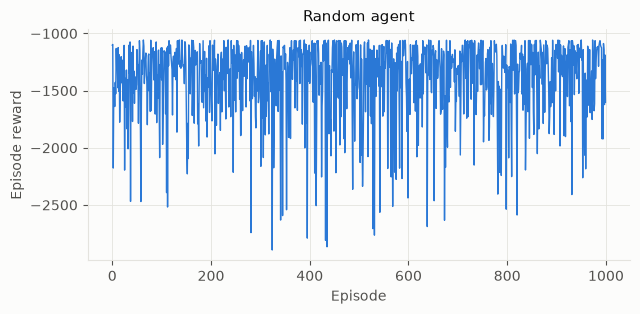

In [9]:
# Initialize the environment and agent
env = CliffBoxGridWorld()
agent = RandomAgent(env, num_episodes=1000)
rewards = agent.learn()

# Plot the learning curve
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(rewards, color=SERIES[0], linewidth=1)
ax.set_xlabel('Episode'); ax.set_ylabel('Episode reward'); ax.set_title('Random agent')
print(f'Random agent: mean reward {np.mean(rewards):.0f}, successes {sum(r > 0 for r in rewards)} / {len(rewards)}')

## 3. Train the Q-learning agent

The success rate below is computed over the last 2000 *training* episodes, so it includes ε-exploration (ε = 0.01 by then).

Training time: 8.2s
Success rate: 0.939
First successful episode: 9376


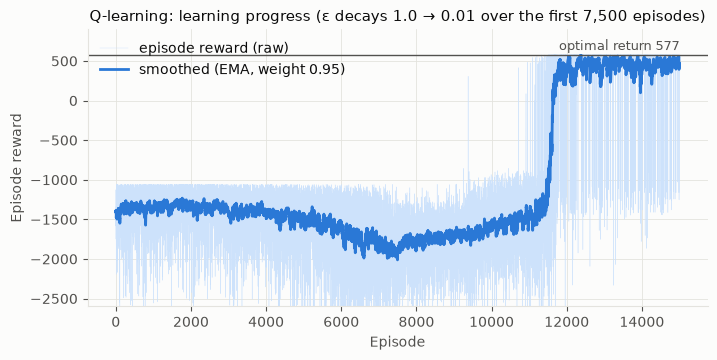

In [10]:
np.random.seed(SEED)
env = CliffBoxGridWorld()
agent = RLAgent(env, num_episodes=MAIN_EPISODES)
start_time = time.time()
rewards = agent.learn()
print(f"Training time: {time.time() - start_time:.1f}s")

# Calculate success rate
final_rewards = np.array(rewards[-2000:])
success_rate = np.sum(final_rewards > 0) / len(final_rewards)
print(f"Success rate: {success_rate}")
first_success = int(np.argmax(agent.successes)) if any(agent.successes) else None
print(f"First successful episode: {first_success}")

# Smooth plot
weight=0.95
last = rewards[0]
smoothed = []
for v in rewards:
    smoothed_val = last * weight + (1 - weight) * v
    smoothed.append(smoothed_val)
    last = smoothed_val

# Plot the learning curve
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(rewards, color='#cde2fb', linewidth=0.3, label='episode reward (raw)')
ax.plot(smoothed, color=SERIES[0], label='smoothed (EMA, weight 0.95)')
ax.axhline(577, color=INK_2, linewidth=1)
ax.text(len(rewards), 600, 'optimal return 577', ha='right', va='bottom', color=INK_2, fontsize=9)
ax.set_xlabel('Episode'); ax.set_ylabel('Episode reward')
ax.set_title('Q-learning: learning progress (ε decays 1.0 → 0.01 over the first 7,500 episodes)')
ax.set_ylim(-2600, 900)
ax.legend(loc='upper left')
save(fig, 'learning_curve.png')
plt.show()

**Reading the curve.** For the first few thousand episodes, ε is large and almost every episode ends at the cliff
(≈ −1000 plus the distance penalties) or in a time-out (≈ −1500 to −2500). As ε shrinks, the optimistic zero-initialised
Q-table pulls the agent into unexplored state-actions. The box is gradually pushed further along the corridor until the goal is
found for the first time, after which the +1000 propagates back through the bootstrapped targets and the curve
climbs to the optimal return of **577** (39 steps; Section 5 verifies optimality exactly by dynamic programming). The remaining dips come from the ε = 0.01 exploration
during training.

## 4. V-table and policy

$V(s) = \max_a Q(s,a)$ and $\pi(s) = \arg\max_a Q(s,a)$. The state is (agent row, agent col, box row, box col), which is
4-dimensional, so we show it in four ways:
1. the template's text output: the 20 largest state values and their greedy actions,
2. the greedy trajectory of the agent and the box,
3. a **policy map for every box position the greedy trajectory visits**. For a fixed box position, each agent cell is coloured by
   $V$ and the arrow is the greedy action (grey cells were never visited during training),
4. an overview of $V$ over box positions: $\max_{\text{agent cell}} V(\text{agent}, \text{box})$.

In [11]:
ACTION_NAMES = {1: 'up', 2: 'down', 3: 'left', 4: 'right'}


def visualize(q_table):
    v_table = {}
    policy = {}
    for key, v in q_table.items():
        v_table[key] = max(v.values())   # V(s) = max_a Q(s, a)
        policy[key] = max(v, key=v.get)  # pi(s) = argmax_a Q(s, a)
    state_num = len(q_table.keys())
    print(f"State space: {state_num}")

    # Print the largest 20 state values in v_table and the corresponding policy
    for k, val in sorted(v_table.items(), key=lambda x: x[1], reverse=True)[:20]:
      print("v_table", k, val / state_num)
      print("policy", k, policy[k], ACTION_NAMES[policy[k]])
    return v_table, policy

v_table, policy = visualize(agent.q_table)

State space: 7056
v_table (2, 13, 3, 13) 0.14143990929705208
policy (2, 13, 3, 13) 2 down
v_table (1, 13, 2, 13) 0.1396003401360543
policy (1, 13, 2, 13) 2 down
v_table (1, 12, 2, 13) 0.1376374433106574
policy (1, 12, 2, 13) 4 right
v_table (2, 12, 2, 13) 0.13555245209750538
policy (2, 12, 2, 13) 1 up
v_table (2, 11, 2, 12) 0.13363003415249397
policy (2, 11, 2, 12) 4 right
v_table (2, 10, 2, 11) 0.1315851170309236
policy (2, 10, 2, 11) 4 right
v_table (2, 9, 2, 10) 0.12941892572455985
policy (2, 9, 2, 10) 4 right
v_table (1, 9, 2, 10) 0.1271326729752507
policy (1, 9, 2, 10) 2 down
v_table (1, 10, 2, 10) 0.12472755939742555
policy (1, 10, 2, 10) 3 left
v_table (0, 10, 1, 10) 0.12248822031138772
policy (0, 10, 1, 10) 2 down
v_table (0, 9, 1, 10) 0.12012955126020122
policy (0, 9, 1, 10) 4 right
v_table (2, 11, 2, 13) 0.11897372592141145
policy (2, 11, 2, 13) 4 right
v_table (1, 9, 1, 10) 0.11765274554351748
policy (1, 9, 1, 10) 1 up
v_table (1, 8, 1, 9) 0.11534243124000967
policy (1, 8, 1

In [12]:
H, W = CliffBoxGridWorld.world_height, CliffBoxGridWorld.world_width
_probe = CliffBoxGridWorld()
CLIFF_CELLS = {(r, c) for r in range(H) for c in range(W) if _probe._check_off_cliff((r, c))}
GOAL_CELL = tuple(CliffBoxGridWorld.goal_pos.tolist())
ARROWS = {1: '↑', 2: '↓', 3: '←', 4: '→'}


def greedy_rollout(agent, action_noise=0.0):
    # Run one episode without exploration; return the visited states, actions, total reward and success flag.
    env = CliffBoxGridWorld()
    state = env.reset()
    states, actions, total, done = [state], [], 0, False
    while not done:
        action = agent.act(state, is_training=False)
        state, reward, done, _ = env.step(apply_action_noise(action, action_noise))
        states.append(state); actions.append(action); total += reward
    return states, actions, total, bool(all(env.box_pos == env.goal_pos))


def draw_world(ax, cell_fontsize=9):
    # Cliffs, goal, grid lines and axis ticks on a (row, col) grid.
    for (r, c) in CLIFF_CELLS:
        ax.add_patch(Rectangle((c - .5, r - .5), 1, 1, color=CLIFF_COLOR, zorder=2))
    ax.add_patch(Rectangle((GOAL_CELL[1] - .5, GOAL_CELL[0] - .5), 1, 1, fill=False, edgecolor=GOAL_COLOR, linewidth=2.5, zorder=4))
    ax.text(GOAL_CELL[1] + .32, GOAL_CELL[0] - .28, 'G', color=GOAL_COLOR, fontsize=cell_fontsize - 2, fontweight='bold', ha='center', va='center', zorder=5)
    ax.set_xlim(-.5, W - .5); ax.set_ylim(H - .5, -.5)
    ax.set_xticks(range(W)); ax.set_yticks(range(H))
    ax.set_xticks(np.arange(-.5, W), minor=True); ax.set_yticks(np.arange(-.5, H), minor=True)
    ax.grid(False); ax.grid(which='minor', color='white', linewidth=1)
    ax.tick_params(which='both', length=0, labelsize=7)
    for s in ax.spines.values():
        s.set_visible(False)


def policy_grid(agent, box):
    # V and greedy action for every agent cell, given a fixed box position (NaN / None if never visited).
    V = np.full((H, W), np.nan)
    A = np.full((H, W), None)
    for r in range(H):
        for c in range(W):
            if (r, c) in CLIFF_CELLS or (r, c) == box:
                continue
            q = agent.q_table[(r, c, *box)]
            if all(v == agent.q_init for v in q.values()):
                continue
            V[r, c] = max(q.values())
            A[r, c] = max(q, key=q.get)
    return V, A


def plot_policy_for_box(ax, agent, box, norm, agent_cell=None, title=None):
    V, A = policy_grid(agent, box)
    ax.imshow(np.ma.masked_invalid(V), cmap=BLUES, norm=norm, zorder=1)
    draw_world(ax)
    for r in range(H):
        for c in range(W):
            if A[r, c] is not None:
                light = norm(V[r, c]) > 0.55
                ax.text(c, r, ARROWS[A[r, c]], ha='center', va='center', fontsize=10,
                        color='white' if light else INK, zorder=3)
    ax.add_patch(Rectangle((box[1] - .42, box[0] - .42), .84, .84, color=BOX_COLOR, zorder=3))
    ax.text(box[1], box[0], 'B', ha='center', va='center', color='white', fontsize=8, fontweight='bold', zorder=4)
    if agent_cell is not None:
        ax.add_patch(Rectangle((agent_cell[1] - .5, agent_cell[0] - .5), 1, 1, fill=False, edgecolor=SERIES[3], linewidth=2.5, zorder=5))
    if title:
        ax.set_title(title, fontsize=9)

Greedy rollout: 39 steps, return 577, success True
Actions: ↑ ↑ ← ↑ → ↑ → ↓ ↓ ↓ ← ↓ → → → ↓ → ↑ ↑ ↑ ← ↑ → → → → → ↑ → ↓ ← ↓ → → → ↑ → ↓ ↓


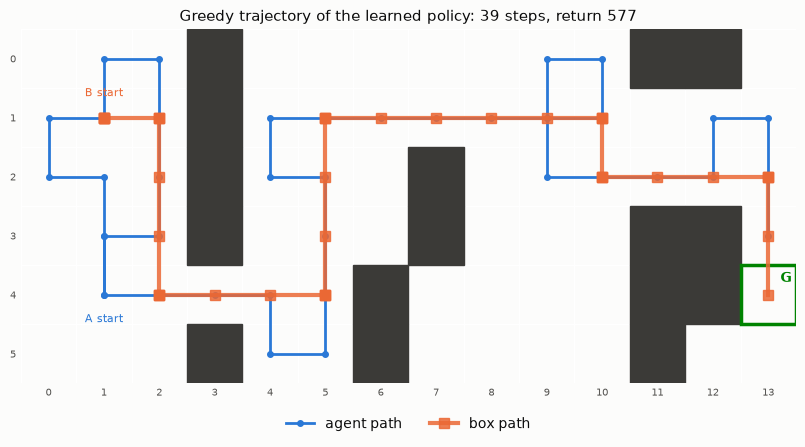

In [13]:
states, actions, total, ok = greedy_rollout(agent)
print(f"Greedy rollout: {len(actions)} steps, return {total}, success {ok}")
print("Actions:", ' '.join(ARROWS[a] for a in actions))

fig, ax = plt.subplots(figsize=(10, 4.6))
draw_world(ax, cell_fontsize=12)
agent_path = np.array([s[:2] for s in states]); box_path = np.array([s[2:] for s in states])
ax.plot(agent_path[:, 1], agent_path[:, 0], color=SERIES[0], marker='o', markersize=4, label='agent path', zorder=6)
ax.plot(box_path[:, 1], box_path[:, 0], color=BOX_COLOR, marker='s', markersize=7, linewidth=3, alpha=.85, label='box path', zorder=7)
ax.text(agent_path[0, 1], agent_path[0, 0] + .32, 'A start', ha='center', va='top', fontsize=8, color=SERIES[0], zorder=8)
ax.text(box_path[0, 1], box_path[0, 0] - .32, 'B start', ha='center', va='bottom', fontsize=8, color=BOX_COLOR, zorder=8)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2)
ax.set_title(f'Greedy trajectory of the learned policy: {len(actions)} steps, return {total}')
save(fig, 'trajectory.png')
plt.show()

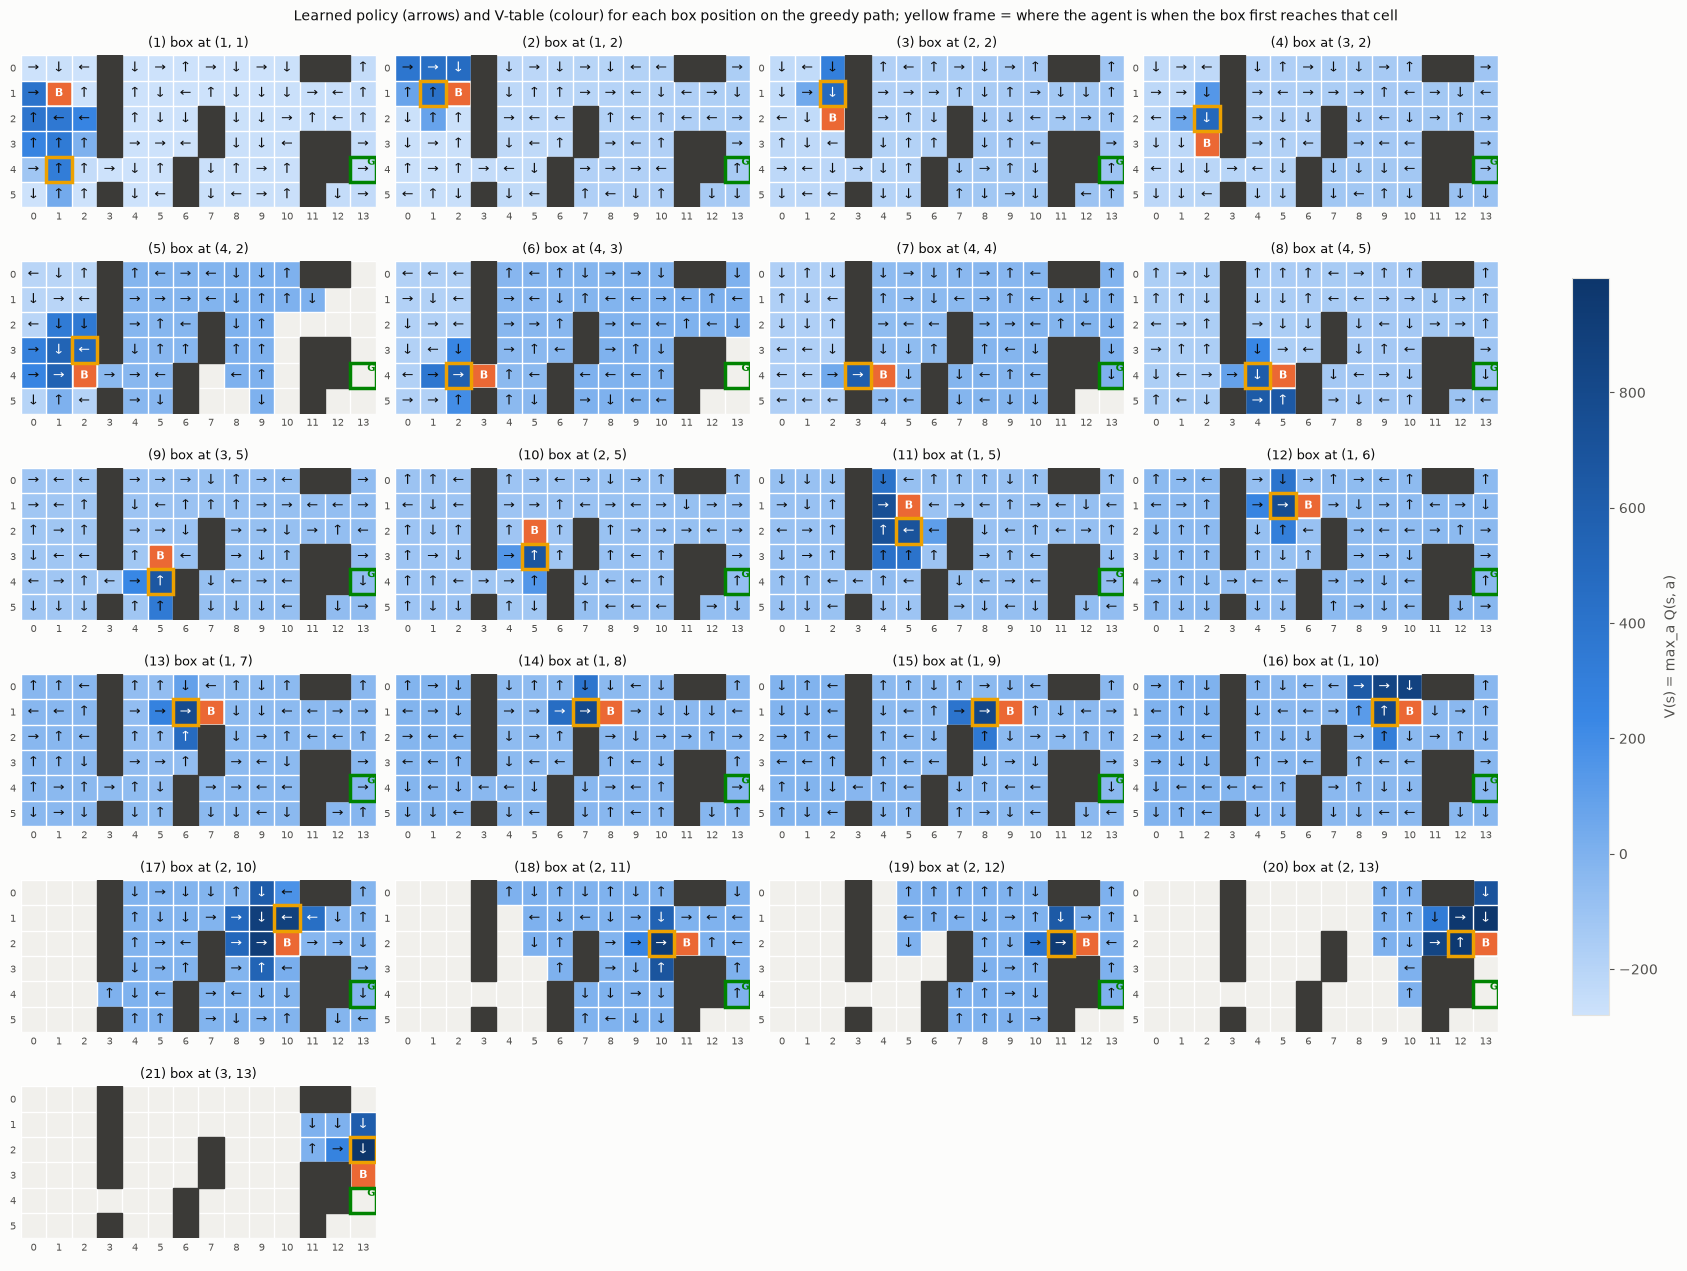

In [14]:
# One policy map per distinct box position on the greedy trajectory.
box_positions, agent_at_box = [], []
for s in states[:-1]:
    if not box_positions or box_positions[-1] != s[2:]:
        box_positions.append(s[2:]); agent_at_box.append(s[:2])

all_V = np.concatenate([policy_grid(agent, b)[0].ravel() for b in box_positions])
norm = plt.Normalize(np.nanpercentile(all_V, 2), np.nanmax(all_V))
ncols = 4
nrows = int(np.ceil(len(box_positions) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 2.1 * nrows), constrained_layout=True)
for k, ax in enumerate(axes.ravel()):
    if k >= len(box_positions):
        ax.axis('off'); continue
    plot_policy_for_box(ax, agent, box_positions[k], norm, agent_cell=agent_at_box[k],
                        title=f'({k + 1}) box at {box_positions[k]}')
sm = plt.cm.ScalarMappable(norm=norm, cmap=BLUES)
fig.colorbar(sm, ax=axes, shrink=0.6, label='V(s) = max_a Q(s, a)')
fig.suptitle('Learned policy (arrows) and V-table (colour) for each box position on the greedy path; '
             'yellow frame = where the agent is when the box first reaches that cell', fontsize=10)
save(fig, 'policy_maps.png')
plt.show()

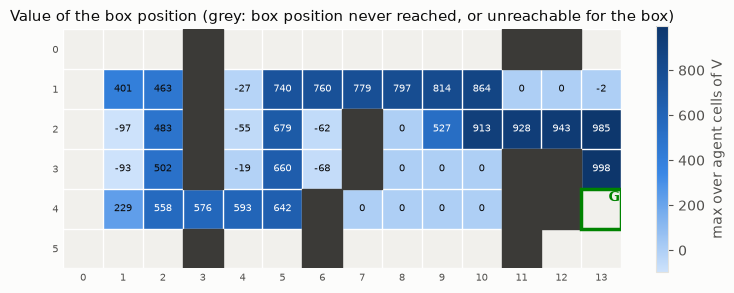

In [15]:
# Value of each box position, taking the best agent cell.
V_box = np.full((H, W), np.nan)
for (r, c) in [(r, c) for r in range(H) for c in range(W)]:
    if (r, c) in CLIFF_CELLS or (r, c) == GOAL_CELL:
        continue
    V, _ = policy_grid(agent, (r, c))
    if not np.all(np.isnan(V)):
        V_box[r, c] = np.nanmax(V)
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(np.ma.masked_invalid(V_box), cmap=BLUES, zorder=1)
draw_world(ax, cell_fontsize=12)
for r in range(H):
    for c in range(W):
        if not np.isnan(V_box[r, c]):
            light = im.norm(V_box[r, c]) > 0.55
            ax.text(c, r, f'{V_box[r, c]:.0f}', ha='center', va='center', fontsize=7, color='white' if light else INK, zorder=3)
fig.colorbar(im, ax=ax, shrink=0.8, label='max over agent cells of V')
ax.set_title('Value of the box position (grey: box position never reached, or unreachable for the box)')
save(fig, 'v_box.png')
plt.show()

**Interpretation.** The agent brings the box down through the only gap in column 3 (row 4), lifts it above the column-6
cliff, slides it along row 1 past the column-7 cliff and through the row 1–2 corridor between the column-11/12 cliffs, then
moves around to push it down column 13 into the goal. Within each panel, the arrows send the agent to the correct side of the
box to make the next push. The values increase steadily along the path towards the goal.

## 5. Evaluation

Evaluate the agent without exploration (ε = 0, deterministic environment).

In [16]:
env = CliffBoxGridWorld(render=True)
total_run = 1000
success = 0

for i in range(total_run):
    state = env.reset()
    done = False
    rewards = []
    
    while not done: 
        action = agent.act(state, is_training=False)
        next_state, reward, done, info = env.step(action)
        state = next_state
        rewards.append(reward)
    if sum(rewards) > 0:
        success += 1
print(success/total_run)

1.0


**Verification against the exact optimum.** The environment is small and deterministic, so we can enumerate all reachable
states and solve the 100-step problem exactly by finite-horizon dynamic programming. This is **only used as a reference**
(never for training). With action noise $p$ the executed action is the chosen one with probability $1-p$ and each other
action with probability $p/3$, so the same DP also gives the best achievable success probability and expected return under
noise, which serves as an upper bound for the robustness study.

In [17]:
def build_model():
    # Enumerate reachable non-terminal states (BFS from the start) and their deterministic transitions.
    sim = CliffBoxGridWorld()
    start = sim.reset()
    index, states_list, frontier = {start: 0}, [start], [start]
    nxt, rew, term = [], [], []
    while frontier:
        new_frontier = []
        for s in frontier:
            row_n, row_r, row_t = [], [], []
            for a in sim.action_space:
                sim.agent_pos, sim.box_pos, sim.timesteps, sim.action_history = np.array(s[:2]), np.array(s[2:]), 0, []
                s2, r, done, _ = sim.step(a)
                if not done and s2 not in index:
                    index[s2] = len(states_list); states_list.append(s2); new_frontier.append(s2)
                row_n.append(index.get(s2, 0) if not done else 0); row_r.append(r); row_t.append(done)
            nxt.append(row_n); rew.append(row_r); term.append(row_t)
        frontier = new_frontier
    rew, term = np.array(rew, float), np.array(term)
    return np.array(nxt), rew, term, term & (rew > 0)


def optimal_reference(p, horizon=100):
    # Finite-horizon DP: maximal expected return and the success probability of that optimal policy.
    nxt, rew, term, goal = MODEL
    M = np.full((4, 4), p / 3); np.fill_diagonal(M, 1 - p)  # M[chosen, executed]
    V = np.zeros(len(nxt)); P = np.zeros(len(nxt))
    for _ in range(horizon):
        Qe = rew + np.where(term, 0, V[nxt])
        Pe = np.where(term, goal, P[nxt])
        Q = Qe @ M.T
        a = Q.argmax(1)
        V, P = Q[np.arange(len(nxt)), a], (Pe @ M.T)[np.arange(len(nxt)), a]
    return V[0], P[0]


MODEL = build_model()
print(f"Reachable non-terminal states: {len(MODEL[0])}")
OPTIMAL = {p: optimal_reference(p) for p in [0.0, 0.1, 0.2]}
for p, (v, s) in OPTIMAL.items():
    print(f"p = {p}: optimal expected return {v:8.1f}, success probability {s:.3f}")
print(f"Learned greedy policy (p = 0): return {total}")

Reachable non-terminal states: 2739
p = 0.0: optimal expected return    577.0, success probability 1.000
p = 0.1: optimal expected return   -278.6, success probability 0.587
p = 0.2: optimal expected return   -942.9, success probability 0.252
Learned greedy policy (p = 0): return 577


Evaluate the agent with exploration and visualization

In [18]:
env = CliffBoxGridWorld(render=True)
state = env.reset()
env.print_world()
done = False
rewards = []

while not done: # Run until game terminated
    action = agent.act(state)
    next_state, reward, done, info = env.step(action)
    state = next_state
    rewards.append(reward)
    print(f'step: {env.timesteps}, state: {state}, actions: {action}, reward: {reward}')
    env.print_world()

print(f'rewards: {sum(rewards)}')
print(f'action history: {env.action_history}')

[[b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'B' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'A' b'_' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'x' b'G']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'_' b'_']]
step: 1, state: (3, 1, 1, 1), actions: 1, reward: -18
Action: 1
[[b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'B' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'A' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'_' b'_' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'x' b'G']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'_' b'_']]
step: 2, state: (2, 1, 1, 1), actions: 1, reward: -17
Acti

## 6. Action-noise robustness study

**Protocol.** In the training/evaluation loop (not in `step()`), with probability $p$ the selected action is replaced by
one of the other three actions uniformly at random. For each $p_{train} \in \{0, 0.1, 0.2\}$ we train **5 independent agents**
(seeds 0–4) with exactly the same agent and hyper-parameters as the main agent, under two budgets:
* **15,000 episodes**, the template's budget, and
* **300,000 episodes**, because the short budget turns out to be far too small once noise is present.

Every trained policy is then evaluated greedily (ε = 0, only the specified action noise) for 1,000 episodes under each
$p_{test} \in \{0, 0.1, 0.2\}$. Tables report the mean over the 5 seeds (± std), and the per-seed results are printed as well.
The training runs are independent, so they are executed in parallel worker processes.

Train three agents with $p_{train}$ in {0, 0.1, 0.2} and compare their episode rewards.

Note: For some RL algorithms, training with action noise may be difficult and may not converge within a reasonable number of episodes. A low or even zero success rate can be a valid experimental result rather than an implementation error. You should report and discuss these results as part of the robustness study.

In [19]:
noise_levels = [0.0, 0.1, 0.2]
noise_runs = {}  # (budget, p_train) -> list of agents (one per seed)

for budget in [NOISE_SHORT_EPISODES, NOISE_LONG_EPISODES]:
    configs = [dict(num_episodes=budget, action_noise=p, seed=s) for p in noise_levels for s in NOISE_SEEDS]
    start_time = time.time()
    agents = train_many(configs)
    print(f"budget {budget}: trained {len(agents)} agents in {time.time() - start_time:.0f}s")
    for cfg, a in zip(configs, agents):
        noise_runs.setdefault((budget, cfg['action_noise']), []).append(a)

# Template variables: one agent per p_train (seed 0, long budget) and its training rewards.
trained_agents = {p: noise_runs[(NOISE_LONG_EPISODES, p)][0] for p in noise_levels}
training_rewards = {p: trained_agents[p].training_rewards for p in noise_levels}

for budget in [NOISE_SHORT_EPISODES, NOISE_LONG_EPISODES]:
    for p in noise_levels:
        firsts = [int(np.argmax(a.successes)) if any(a.successes) else None for a in noise_runs[(budget, p)]]
        print(f"budget {budget:>7}, p_train={p}: first successful training episode per seed = {firsts}")

budget 15000: trained 15 agents in 22s


budget 300000: trained 15 agents in 442s
budget   15000, p_train=0.0: first successful training episode per seed = [10866, 11056, 10841, 10700, 10717]
budget   15000, p_train=0.1: first successful training episode per seed = [None, None, None, None, None]
budget   15000, p_train=0.2: first successful training episode per seed = [None, None, None, None, None]
budget  300000, p_train=0.0: first successful training episode per seed = [113455, 113457, 110789, 113438, 112698]
budget  300000, p_train=0.1: first successful training episode per seed = [160975, 153196, 140904, 146384, 152726]
budget  300000, p_train=0.2: first successful training episode per seed = [160038, 176617, 219098, 186571, 176615]


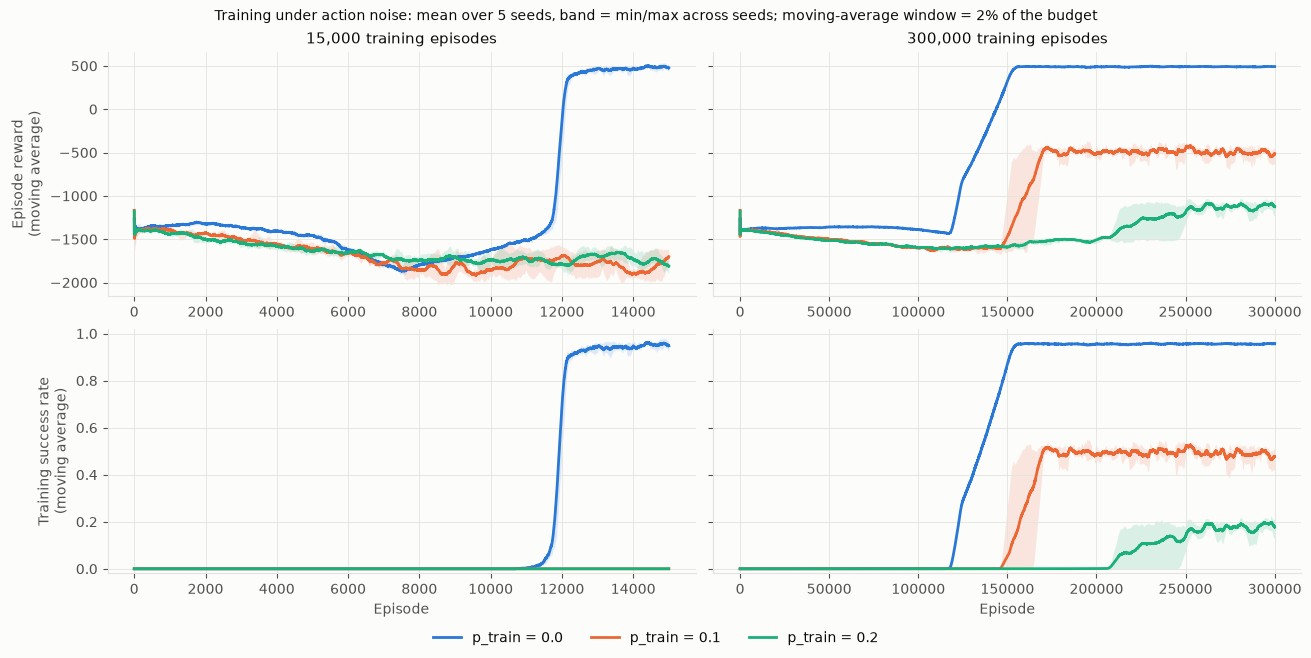

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharey='row', constrained_layout=True)
for col, budget in enumerate([NOISE_SHORT_EPISODES, NOISE_LONG_EPISODES]):
    window = budget // 50
    for k, p in enumerate(noise_levels):
        runs = noise_runs[(budget, p)]
        x = np.arange(budget)
        R = np.array([moving_average(a.training_rewards, window) for a in runs])
        S = np.array([moving_average(a.successes, window) for a in runs])
        for row, Y in enumerate([R, S]):
            ax = axes[row, col]
            ax.fill_between(x, np.nanmin(Y, 0), np.nanmax(Y, 0), color=SERIES[k], alpha=0.15, linewidth=0)
            ax.plot(x, np.nanmean(Y, 0), color=SERIES[k], label=f'p_train = {p}')
    axes[0, col].set_title(f'{budget:,} training episodes')
    axes[1, col].set_xlabel('Episode')
axes[0, 0].set_ylabel(f'Episode reward\n(moving average)')
axes[1, 0].set_ylabel('Training success rate\n(moving average)')
axes[1, 0].set_ylim(-0.02, 1.02)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3)
fig.suptitle(f'Training under action noise: mean over {len(NOISE_SEEDS)} seeds, band = min/max across seeds; '
             'moving-average window = 2% of the budget', fontsize=10)
save(fig, 'noise_training_curves.png')
plt.show()

You need to complete the following method to evaluate the trained agents under action noise. During evaluation, disable exploration and keep only the specified action noise.

In [21]:
def evaluate(agent, p_test, total_run=100):
    env = CliffBoxGridWorld()
    success = 0
    episode_returns = []

    for _ in range(total_run):
        state = env.reset()
        done = False
        rewards = []

        while not done:
            action = agent.act(state, is_training=False)    # greedy: no exploration
            action = apply_action_noise(action, p_test)     # only the specified action noise
            state, reward, done, info = env.step(action)
            rewards.append(reward)

        if all(env.box_pos == env.goal_pos):
            success += 1
        episode_returns.append(sum(rewards))

    return success / total_run, np.mean(episode_returns)


np.random.seed(SEED)
results = {}  # budget -> (success array [seed, p_train, p_test], return array)
for budget in [NOISE_SHORT_EPISODES, NOISE_LONG_EPISODES]:
    sr = np.zeros((len(NOISE_SEEDS), 3, 3)); ret = np.zeros((len(NOISE_SEEDS), 3, 3))
    for i, p_train in enumerate(noise_levels):
        for k, a in enumerate(noise_runs[(budget, p_train)]):
            for j, p_test in enumerate(noise_levels):
                sr[k, i, j], ret[k, i, j] = evaluate(a, p_test, total_run=EVAL_EPISODES)
    results[budget] = (sr, ret)

success_rate = results[NOISE_LONG_EPISODES][0].mean(0)
average_return = results[NOISE_LONG_EPISODES][1].mean(0)

for budget, (sr, ret) in results.items():
    print(f"\n=== Budget: {budget:,} episodes (mean over {len(NOISE_SEEDS)} seeds) ===")
    print("Rows: p_train =", noise_levels)
    print("Columns: p_test =", noise_levels)
    print("Success rate:")
    print(sr.mean(0).round(3))
    print("Average episode return:")
    print(ret.mean(0).round(1))
    print("Per-seed success rate at p_test = p_train:",
          {p: sr[:, i, i].round(2).tolist() for i, p in enumerate(noise_levels)})
print("\nDP optimum (upper bound) for p_test = 0 / 0.1 / 0.2: success",
      ' / '.join(f'{OPTIMAL[p][1]:.3f}' for p in noise_levels), "; return", ' / '.join(f'{OPTIMAL[p][0]:.1f}' for p in noise_levels))

print("\nPer-seed results, long budget (success rate at p_test = 0 / 0.1 / 0.2 | return at p_test = 0.1):")
sr, ret = results[NOISE_LONG_EPISODES]
for i, p in enumerate(noise_levels):
    for k, s in enumerate(NOISE_SEEDS):
        print(f"  p_train={p} seed={s}: SR " + ' / '.join(f'{v:.3f}' for v in sr[k, i]) + f" | R {ret[k, i, 1]:7.1f}")


=== Budget: 15,000 episodes (mean over 5 seeds) ===
Rows: p_train = [0.0, 0.1, 0.2]
Columns: p_test = [0.0, 0.1, 0.2]
Success rate:
[[1.    0.432 0.111]
 [0.    0.    0.   ]
 [0.    0.    0.   ]]
Average episode return:
[[  577.   -546.  -1179.6]
 [-1348.4 -1563.3 -1574.9]
 [-1853.2 -1830.1 -1763.2]]
Per-seed success rate at p_test = p_train: {0.0: [1.0, 1.0, 1.0, 1.0, 1.0], 0.1: [0.0, 0.0, 0.0, 0.0, 0.0], 0.2: [0.0, 0.0, 0.0, 0.0, 0.0]}

=== Budget: 300,000 episodes (mean over 5 seeds) ===
Rows: p_train = [0.0, 0.1, 0.2]
Columns: p_test = [0.0, 0.1, 0.2]
Success rate:
[[1.    0.494 0.168]
 [0.8   0.536 0.231]
 [0.8   0.449 0.184]]
Average episode return:
[[  577.   -410.8 -1035.8]
 [  322.2  -388.1 -1013.5]
 [  285.   -533.1 -1096.5]]
Per-seed success rate at p_test = p_train: {0.0: [1.0, 1.0, 1.0, 1.0, 1.0], 0.1: [0.58, 0.36, 0.58, 0.57, 0.59], 0.2: [0.24, 0.01, 0.2, 0.24, 0.23]}

DP optimum (upper bound) for p_test = 0 / 0.1 / 0.2: success 1.000 / 0.587 / 0.252 ; return 577.0 / -27

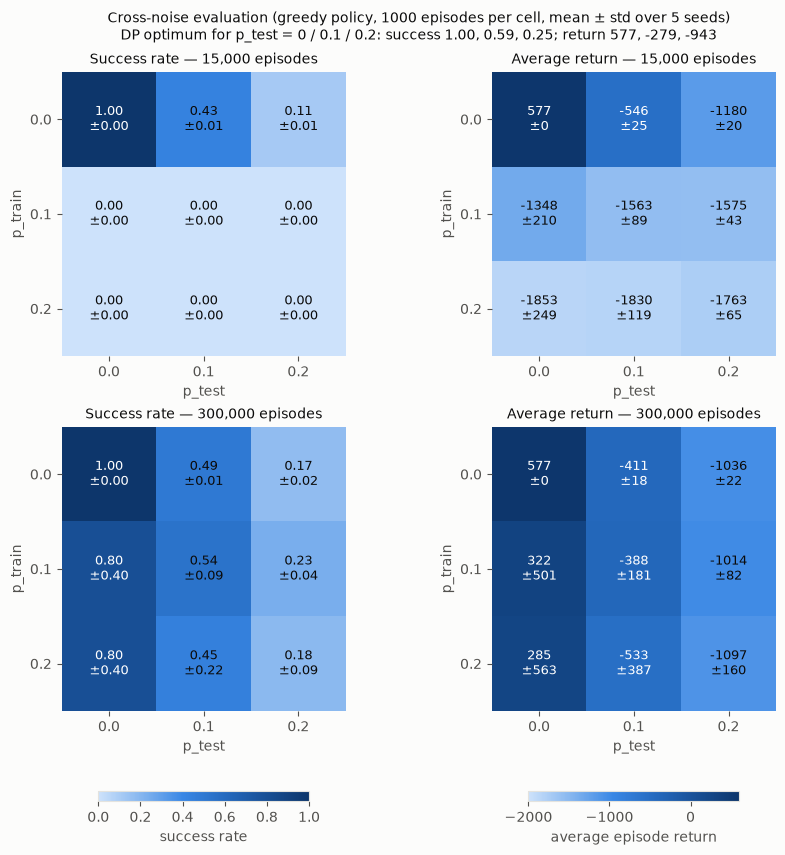

In [22]:
def heatmap(ax, mean, std, title, fmt, vmin, vmax):
    im = ax.imshow(mean, cmap=BLUES, vmin=vmin, vmax=vmax)
    for i in range(3):
        for j in range(3):
            light = im.norm(mean[i, j]) > 0.55
            ax.text(j, i, f'{mean[i, j]:{fmt}}\n±{std[i, j]:{fmt}}', ha='center', va='center',
                    fontsize=9, color='white' if light else INK)
    ax.set_xticks(range(3), [f'{p}' for p in noise_levels]); ax.set_yticks(range(3), [f'{p}' for p in noise_levels])
    ax.set_xlabel('p_test'); ax.set_ylabel('p_train'); ax.set_title(title, fontsize=10); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return im


fig, axes = plt.subplots(2, 2, figsize=(8.6, 8.4), constrained_layout=True)
for row, budget in enumerate([NOISE_SHORT_EPISODES, NOISE_LONG_EPISODES]):
    sr, ret = results[budget]
    im0 = heatmap(axes[row, 0], sr.mean(0), sr.std(0), f'Success rate — {budget:,} episodes', '.2f', 0, 1)
    im1 = heatmap(axes[row, 1], ret.mean(0), ret.std(0), f'Average return — {budget:,} episodes', '.0f', -2000, 600)
fig.colorbar(im0, ax=axes[:, 0], shrink=0.5, location='bottom', label='success rate')
fig.colorbar(im1, ax=axes[:, 1], shrink=0.5, location='bottom', label='average episode return')
opt_sr = ', '.join(f'{OPTIMAL[p][1]:.2f}' for p in noise_levels)
opt_ret = ', '.join(f'{OPTIMAL[p][0]:.0f}' for p in noise_levels)
fig.suptitle(f'Cross-noise evaluation (greedy policy, {EVAL_EPISODES} episodes per cell, mean ± std over {len(NOISE_SEEDS)} seeds)\n'
             f'DP optimum for p_test = 0 / 0.1 / 0.2: success {opt_sr}; return {opt_ret}', fontsize=10)
save(fig, 'noise_heatmaps.png')
plt.show()

In [23]:
# Greedy noiseless path of each long-budget agent (seed 0) that solves the noiseless task: does noise make it more careful?
for p in noise_levels:
    for k, a in enumerate(noise_runs[(NOISE_LONG_EPISODES, p)]):
        st, ac, tot, ok = greedy_rollout(a)
        print(f"p_train={p} seed={k}: noiseless greedy return {tot:5d}, steps {len(ac):3d}, success {ok}")

p_train=0.0 seed=0: noiseless greedy return   577, steps  39, success True
p_train=0.0 seed=1: noiseless greedy return   577, steps  39, success True
p_train=0.0 seed=2: noiseless greedy return   577, steps  39, success True
p_train=0.0 seed=3: noiseless greedy return   577, steps  39, success True
p_train=0.0 seed=4: noiseless greedy return   577, steps  39, success True
p_train=0.1 seed=0: noiseless greedy return   571, steps  39, success True
p_train=0.1 seed=1: noiseless greedy return  -679, steps 100, success False
p_train=0.1 seed=2: noiseless greedy return   573, steps  39, success True
p_train=0.1 seed=3: noiseless greedy return   573, steps  39, success True
p_train=0.1 seed=4: noiseless greedy return   573, steps  39, success True
p_train=0.2 seed=0: noiseless greedy return   550, steps  41, success True
p_train=0.2 seed=1: noiseless greedy return  -840, steps 100, success False
p_train=0.2 seed=2: noiseless greedy return   573, steps  39, success True
p_train=0.2 seed=3: noi

**Discussion — see the report for the full analysis.** Main observations:
* **Action noise makes learning far harder.** With 15k episodes the noise-free agents converge, but the noisy agents
  never reach the goal even once during training. Slips near the narrow box corridors keep sending the box (or the agent)
  over the cliff, so the optimism-driven exploration never pushes the box far enough to find the +1000.
* **With a longer budget, moderate noise ($p_{train}=0.1$) converges reliably and yields the most robust policy.** It beats the
  noise-free policy at $p_{test} = 0.1$ and $0.2$, close to the DP optimum, and still solves the noiseless task, using a slightly
  longer and safer route (return a little below 577).
* **Heavy noise ($p_{train}=0.2$) is unreliable**: within the same budget only some seeds discover and keep the goal-reaching
  behaviour, and the others converge to "avoid the cliff and wait for the time-out".

## 7. Bonus A — exploration strategies

All agents use the same Q-learning update ($\alpha=0.1, \gamma=0.99$), 15,000 episodes, no action noise, 3 seeds. Only the
behaviour policy (and, for the last baseline, the initial Q-values) changes:

| Strategy | Behaviour policy |
|---|---|
| ε-greedy, decaying (main agent) | ε linearly 1.0 → 0.01 over the first half |
| ε-greedy, constant ε = 0.1 | the template's default |
| UCB1 | $\arg\max_a Q(s,a) + c\sqrt{\ln N(s)/N(s,a)}$ with $c = 10$, untried actions first |
| No exploration, $Q_0 = 0$ | always greedy (random tie-breaking) |
| No exploration, $Q_0 = -3000$ | always greedy, pessimistic initial values |

In [24]:
class UCBAgent(RLAgent):
    # Q-learning with UCB1 action selection: argmax_a Q(s,a) + c * sqrt(ln N(s) / N(s,a)).
    def __init__(self, env, num_episodes, c=10.0, **kwargs):
        kwargs.update(epsilon=0.0, epsilon_min=0.0)
        super().__init__(env, num_episodes, **kwargs)
        self.c = c
        self.counts = {s: {a: 0 for a in self.action_space} for s in self.q_table}

    def act(self, state, is_training=True):
        if not is_training:
            return self.greedy_action(state)
        n = self.counts[state]
        untried = [a for a in self.action_space if n[a] == 0]
        if untried:
            action = untried[np.random.randint(0, len(untried))]
        else:
            q = self.q_table[state]
            log_total = np.log(sum(n.values()))
            scores = {a: q[a] + self.c * np.sqrt(log_total / n[a]) for a in self.action_space}
            best = max(scores.values())
            candidates = [a for a, v in scores.items() if v == best]
            action = candidates[np.random.randint(0, len(candidates))]
        n[action] += 1
        return action


EXPLORATION = {
    'ε-greedy, decaying (main)': dict(),
    'ε-greedy, constant ε=0.1': dict(epsilon=0.1, epsilon_min=0.1),
    'UCB1, c=10': dict(agent_cls=UCBAgent, c=10.0),
    'No exploration, Q0=0': dict(epsilon=0.0, epsilon_min=0.0),
    'No exploration, Q0=-3000': dict(epsilon=0.0, epsilon_min=0.0, q_init=-3000.0),
}
configs = [dict(cfg, num_episodes=BONUS_EPISODES, seed=s) for cfg in EXPLORATION.values() for s in BONUS_SEEDS]
start_time = time.time()
agents = train_many(configs)
print(f"Trained {len(agents)} agents in {time.time() - start_time:.0f}s")
exploration_runs = {name: agents[i * len(BONUS_SEEDS):(i + 1) * len(BONUS_SEEDS)] for i, name in enumerate(EXPLORATION)}

Trained 15 agents in 41s


strategy                     goal found 1st success mean train R train SR last-1k SR greedy SR greedy R
ε-greedy, decaying (main)         3 / 3       10921        -1106    0.203      0.949      1.00      577
ε-greedy, constant ε=0.1          3 / 3        7924        -1213    0.185      0.571      1.00      577
UCB1, c=10                        3 / 3        4526         -330    0.605      1.000      1.00      577
No exploration, Q0=0              3 / 3        4719         -301    0.618      1.000      1.00      577
No exploration, Q0=-3000          0 / 3         nan        -2000    0.000      0.000      0.00    -2000


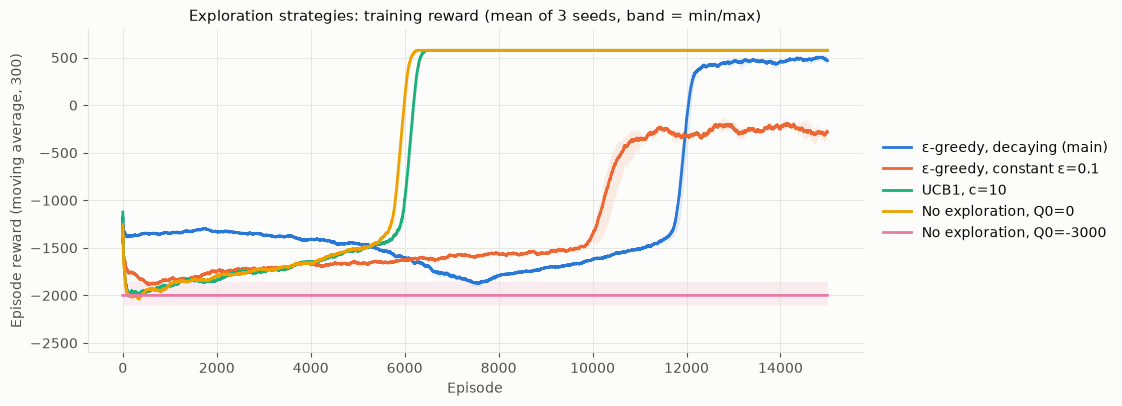

In [25]:
def summarize(runs, eval_runs=1):
    # Per-strategy metrics, averaged over seeds.
    rows = []
    for name, agents_ in runs.items():
        firsts = [int(np.argmax(a.successes)) if any(a.successes) else np.nan for a in agents_]
        greedy = [greedy_rollout(a) for a in agents_]
        rows.append(dict(
            name=name,
            first=np.nanmean(firsts) if not np.all(np.isnan(firsts)) else np.nan,
            found=sum(not np.isnan(f) for f in firsts),
            mean_train=np.mean([np.mean(a.training_rewards) for a in agents_]),
            train_sr=np.mean([np.mean(a.successes) for a in agents_]),
            last_sr=np.mean([np.mean(a.successes[-1000:]) for a in agents_]),
            greedy_sr=np.mean([g[3] for g in greedy]),
            greedy_ret=np.mean([g[2] for g in greedy]),
        ))
    print(f"{'strategy':28s} {'goal found':>10s} {'1st success':>11s} {'mean train R':>12s} {'train SR':>8s} "
          f"{'last-1k SR':>10s} {'greedy SR':>9s} {'greedy R':>8s}")
    for r in rows:
        print(f"{r['name']:28s} {r['found']:>6d} / {len(BONUS_SEEDS)} {r['first']:>11.0f} {r['mean_train']:>12.0f} "
              f"{r['train_sr']:>8.3f} {r['last_sr']:>10.3f} {r['greedy_sr']:>9.2f} {r['greedy_ret']:>8.0f}")
    return rows


def plot_runs(runs, key, ylabel, title, fname, window=300, ylim=None):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for k, (name, agents_) in enumerate(runs.items()):
        Y = np.array([moving_average(getattr(a, key), window) for a in agents_])
        x = np.arange(Y.shape[1])
        ax.fill_between(x, np.nanmin(Y, 0), np.nanmax(Y, 0), color=SERIES[k], alpha=0.12, linewidth=0)
        ax.plot(x, np.nanmean(Y, 0), color=SERIES[k], label=name)
    ax.set_xlabel('Episode'); ax.set_ylabel(ylabel); ax.set_title(title)
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
    save(fig, fname)
    plt.show()


exploration_table = summarize(exploration_runs)
plot_runs(exploration_runs, 'training_rewards', 'Episode reward (moving average, 300)',
          'Exploration strategies: training reward (mean of 3 seeds, band = min/max)', 'bonus_exploration.png',
          ylim=(-2600, 800))

**Analysis** (numbers from the table above; 3 seeds each).
* **The two optimism-driven strategies are clearly best.** UCB1 and "no exploration" with $Q_0=0$ both find the goal after
  ≈4.5k episodes and reach a 100% training success rate. They also have by far the highest mean training reward (≈ −300 vs. ≈ −1100 to −1200 for ε-greedy).
* **"No exploration" with $Q_0 = 0$ is not actually exploration-free.** Every real reward is negative, so 0 is an *optimistic* estimate.
  Each time a state-action is tried its value drops below the untried ones, so the greedy agent systematically sweeps through the
  state space (optimism in the face of uncertainty).
* With a **pessimistic** $Q_0 = -3000$, the same greedy agent never finds the goal (0/3). Every tried action looks *better* than the untried
  ones, so the agent keeps repeating what it already knows. This shows that the initial values are what make the greedy agent explore.
* **UCB1** turns uncertainty into an explicit bonus that shrinks with the visit count. Its exploration is *directed* (towards rarely tried actions) rather than
  random. In preliminary runs a large $c$ (100–500, comparable to the reward scale) over-explored and converged later or not at all.
* **ε-greedy explores by undirected dithering, which suits this task poorly.** A successful episode needs about 40 consecutive correct
  actions next to cliffs, and a single random action can push the box over the edge. With decaying ε the goal is first reached only
  after ε has fallen to its floor (≈10.9k episodes, against 7.5k for the decay), so the high-ε phase mostly produces cliff deaths. Constant ε = 0.1 finds the goal
  earlier (≈7.9k) but keeps paying for its random actions: only 57% of its last 1,000 training episodes succeed (95% with decaying ε).
* All strategies except the pessimistic one end with the optimal greedy policy (return 577).

## 8. Bonus B — sparse reward

The learning signal is now **only** $r = 1000$ when the box reaches the goal and $0$ otherwise (no step cost, no distance shaping,
no cliff penalty, though falling still ends the episode). Before the goal is first reached, every update is $0 \to 0$, so the Q-table
gives no guidance at all: ε-greedy or a greedy agent with $Q_0 = 0$ is a pure random walk, and a random walk practically never
pushes the box 15+ cells along a cliff-lined corridor.

**Idea: deep exploration by optimistic initial values.** Initialise $Q_0 > 0$ and act greedily. With zero rewards the update
$Q(s,a) \leftarrow (1-\alpha)Q(s,a) + \alpha\gamma\max_{a'}Q(s',a')$ shrinks the value of everything already tried, while untried
state-actions keep their optimistic value. Through the bootstrapped $\max$, this optimism is propagated *backwards*: the agent
plans multi-step routes towards the frontier of unexplored states, rather than dithering locally (similar in spirit to R-max).
Falling off the cliff ends the episode and forfeits all future optimism, so the agent also learns to avoid cliffs without
ever being penalised. Once the goal is found, its real +1000 takes over.

Trained 12 agents in 26s
strategy                     goal found 1st success mean train R train SR last-1k SR greedy SR greedy R
ε-greedy (decaying), Q0=0         0 / 3         nan        -1392    0.000      0.000      0.00    -1596
Greedy, Q0=0                      0 / 3         nan        -1392    0.000      0.000      0.00    -1377
Greedy, optimistic Q0=100         3 / 3        9873        -1199    0.241      1.000      1.00      572
Greedy, optimistic Q0=1000        3 / 3        9890        -1698    0.004      0.037      0.00    -1430


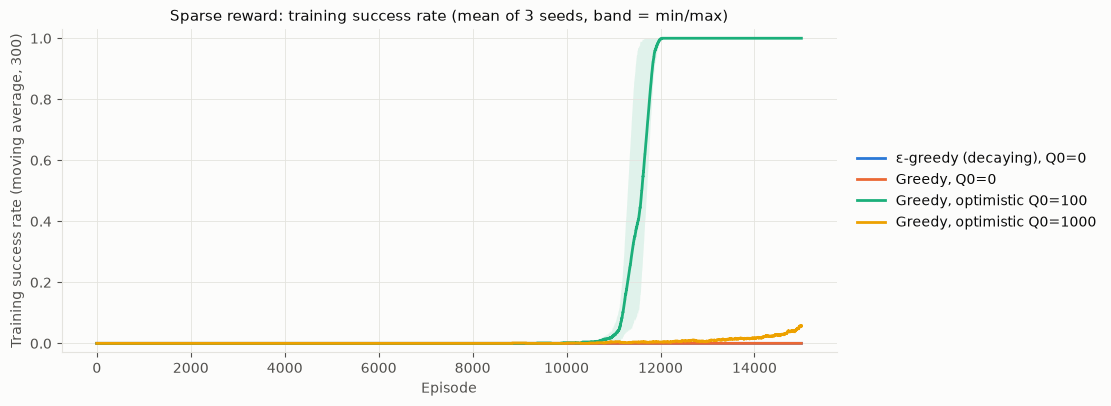

In [26]:
SPARSE = {
    'ε-greedy (decaying), Q0=0': dict(),
    'Greedy, Q0=0': dict(epsilon=0.0, epsilon_min=0.0),
    'Greedy, optimistic Q0=100': dict(epsilon=0.0, epsilon_min=0.0, q_init=100.0),
    'Greedy, optimistic Q0=1000': dict(epsilon=0.0, epsilon_min=0.0, q_init=1000.0),
}
configs = [dict(cfg, num_episodes=BONUS_EPISODES, seed=s, sparse_reward=True) for cfg in SPARSE.values() for s in BONUS_SEEDS]
start_time = time.time()
agents = train_many(configs)
print(f"Trained {len(agents)} agents in {time.time() - start_time:.0f}s")
sparse_runs = {name: agents[i * len(BONUS_SEEDS):(i + 1) * len(BONUS_SEEDS)] for i, name in enumerate(SPARSE)}

for a in agents:
    a.training_successes = np.array(a.successes, dtype=float)
sparse_table = summarize(sparse_runs)
plot_runs(sparse_runs, 'training_successes', 'Training success rate (moving average, 300)',
          'Sparse reward: training success rate (mean of 3 seeds, band = min/max)', 'bonus_sparse.png', ylim=(-0.03, 1.03))

Sparse-reward agent (Q0=100): 39 steps, success True, return under the ORIGINAL reward 569
Actions: ↑ ↑ ← ↑ ↑ → ↓ ↓ ↓ ← ↓ → → → → ↓ → ↑ ↑ ↑ ← ↑ → → → → ↑ → ↓ ← ↓ → → → → ↑ → ↓ ↓


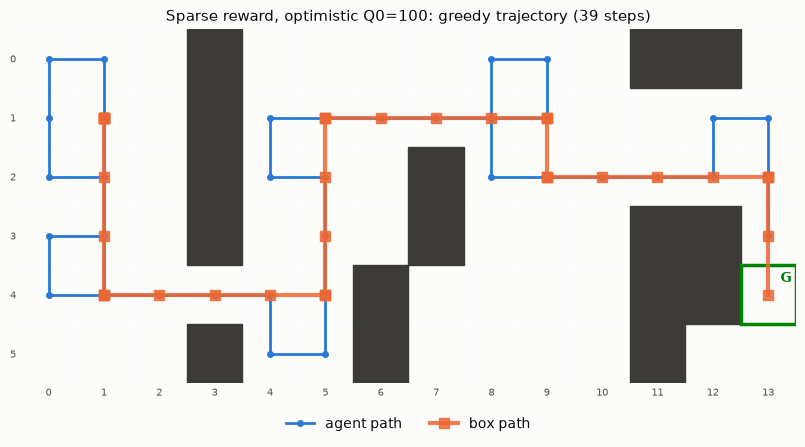

In [27]:
# Learned policy of the best sparse-reward agent.
best = sparse_runs['Greedy, optimistic Q0=100'][0]
st, ac, tot, ok = greedy_rollout(best)
print(f"Sparse-reward agent (Q0=100): {len(ac)} steps, success {ok}, return under the ORIGINAL reward {tot}")
print("Actions:", ' '.join(ARROWS[a] for a in ac))
fig, ax = plt.subplots(figsize=(10, 4.6))
draw_world(ax, cell_fontsize=12)
ap = np.array([s[:2] for s in st]); bp = np.array([s[2:] for s in st])
ax.plot(ap[:, 1], ap[:, 0], color=SERIES[0], marker='o', markersize=4, label='agent path', zorder=6)
ax.plot(bp[:, 1], bp[:, 0], color=BOX_COLOR, marker='s', markersize=7, linewidth=3, alpha=.85, label='box path', zorder=7)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2)
ax.set_title(f'Sparse reward, optimistic Q0=100: greedy trajectory ({len(ac)} steps)')
save(fig, 'sparse_trajectory.png')
plt.show()

**Analysis** (numbers from the table above; 3 seeds each).
* ε-greedy and greedy-with-$Q_0=0$ never see a single success in 15k episodes, so their Q-tables stay at zero (0/3 seeds).
* **Optimistic $Q_0 = 100$ with greedy action selection solves the sparse task for every seed.** The goal is first reached after ≈9.9k
  episodes, the last 1,000 training episodes all succeed, and the greedy policy reaches the goal in 39 steps (the minimum, the same as the dense-reward
  optimum), with a return of ≈572 under the original reward (optimum 577).
* **Too much optimism prevents exploitation.** $Q_0 = 1000$ also finds the goal (≈9.9k episodes) but does not converge within 15k
  episodes (greedy success 0/3). The discounted value of the real solution from the start is only about $1000\,\gamma^{38} \approx 680$, so every
  untried state-action anywhere in the state space still looks better than the known route. The agent therefore keeps exploring until all of that
  optimism has worn off. The optimistic value should be large enough to beat dead ends (worth 0) but below the value of a real solution.